# 03 — Sensitivity analysis

How does annual loss change when claims become more frequent, more
expensive, or both?

- **Baseline** uses the original assumptions.
- **Higher frequency** increases expected claims per policy-year by 25%.
- **Higher severity** increases the mean and standard deviation of claim
  payments by 25%, keeping their ratio constant.
- **Combined stress** applies both increases.

Each scenario uses 50,000 simulated years, seed 42, and the same
CAD 350,000 exceedance threshold.

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation import BASELINE, simulate_annual_losses, summarize_annual_losses

In [2]:
stress_factor = 1.25
threshold = 350_000

frequency_stress = {
    "frequency": BASELINE["frequency"] * stress_factor,
}
severity_stress = {
    "severity_mean": BASELINE["severity_mean"] * stress_factor,
    "severity_std_dev": BASELINE["severity_std_dev"] * stress_factor,
}

scenarios = {
    "Baseline": {},
    "Higher frequency": frequency_stress,
    "Higher severity": severity_stress,
    "Combined stress": {**frequency_stress, **severity_stress},
}

scenario_results = {}

for name, overrides in scenarios.items():
    inputs = {**BASELINE, **overrides}
    losses = simulate_annual_losses(**inputs)
    scenario_results[name] = summarize_annual_losses(losses, threshold=threshold)

print(f"Loss amounts in CAD. Exceedance threshold: CAD {threshold:,.0f}")
print(f"{'Scenario':<20}{'Mean loss':>13}{'99% VaR':>13}{'99% TVaR':>13}{'Exceedance':>13}")

for name, risk in scenario_results.items():
    print(
        f"{name:<20}"
        f"{risk['mean']:>13,.0f}"
        f"{risk['var_99']:>13,.0f}"
        f"{risk['tvar_99']:>13,.0f}"
        f"{risk['exceedance_probability']:>13.2%}"
    )

Loss amounts in CAD. Exceedance threshold: CAD 350,000
Scenario                Mean loss      99% VaR     99% TVaR   Exceedance
Baseline                  250,157      433,156      483,911        6.96%
Higher frequency          312,827      513,619      571,695       26.84%
Higher severity           312,696      541,445      604,888       28.17%
Combined stress           391,034      642,023      714,619       65.45%


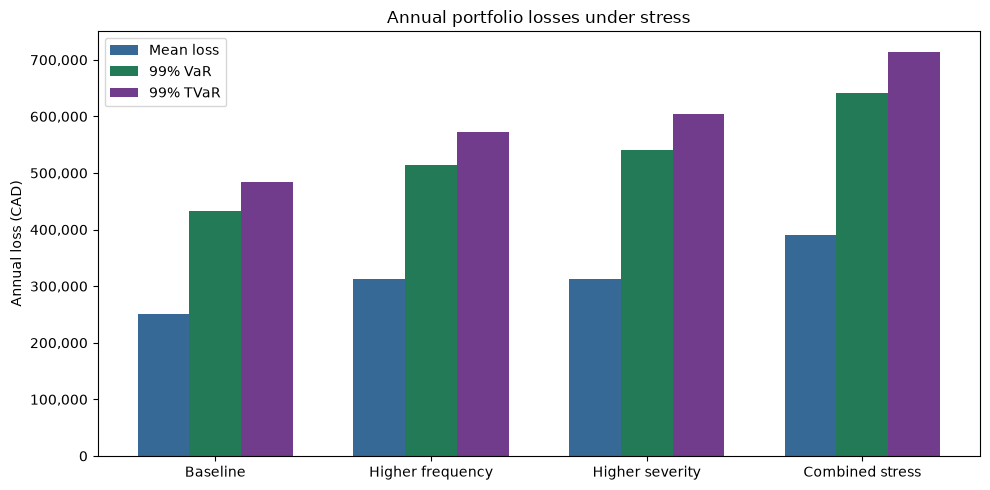

Saved figure to /Users/eloisefang/Downloads/monte-carlo-insurance-risk/figures/scenario_comparison.png


In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np

scenario_names = list(scenario_results)
positions = np.arange(len(scenario_names))
bar_width = 0.24

metrics = [
    ("mean", "Mean loss", "#376996"),
    ("var_99", "99% VaR", "#237a57"),
    ("tvar_99", "99% TVaR", "#703c8b"),
]

fig, ax = plt.subplots(figsize=(10, 5))

for offset, (key, label, color) in enumerate(metrics, start=-1):
    values = [scenario_results[name][key] for name in scenario_names]
    ax.bar(
        positions + offset * bar_width,
        values,
        width=bar_width,
        label=label,
        color=color,
    )

ax.set_xticks(positions, scenario_names)
ax.set(
    title="Annual portfolio losses under stress",
    ylabel="Annual loss (CAD)",
)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left")
fig.tight_layout()

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)
output_path = figures_dir / "scenario_comparison.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to {output_path}")

### Scenario findings

The higher-frequency and higher-severity scenarios both have an
analytical mean annual loss of CAD 312,500. Their simulated means
are close, but the average loss in the worst 1% of years is higher
under severity stress: CAD 604,888 versus CAD 571,695 under
frequency stress. In this model, increasing the size and spread of
individual payments produces more variability in annual losses.

Under combined stress, 65.45% of simulated years exceeded
CAD 350,000, compared with 6.96% in the baseline.